*Clustering:*

In [3]:
import pandas as pd
import numpy as np
import os

pd.set_option('display.max_columns', None)

df = pd.read_csv('../data/processed/player_master_clean.csv', parse_dates=['date_of_birth'])
df['valuation_date'] = pd.to_datetime(df['valuation_date'])
df['age'] = (df['valuation_date'] - df['date_of_birth']).dt.days // 365
df.shape

(27607, 34)

In [4]:
d = df[df['total_minutes'] >= 900].copy()

d['goals_per90']   = d['total_goals'] / d['total_minutes'] * 90
d['assists_per90'] = d['total_assists'] / d['total_minutes'] * 90
d['yellows_per90'] = d['total_yellow_cards'] / d['total_minutes'] * 90
d['log_minutes']   = np.log10(d['total_minutes'])
d['log_caps']      = np.log1p(d['international_caps'])
d['log_value']     = np.log10(d['market_value_in_eur'])

features = ['age', 'height_in_cm', 'log_minutes', 'goals_per90',
            'assists_per90', 'yellows_per90', 'log_caps', 'log_value']

print(d.shape)
d[features].describe()

(17218, 40)


,age,height_in_cm,log_minutes,goals_per90,assists_per90,yellows_per90,log_caps,log_value
count,17218.000000,17218.000000,17218.000000,17218.000000,17218.000000,17218.000000,17218.000000,17218.000000
mean,29.812986,182.435649,3.676888,0.117078,0.089377,0.199379,0.832622,5.761760
std,4.705152,6.609747,0.406356,0.137399,0.085497,0.115592,1.294884,0.712017
min,17.000000,159.000000,2.954243,0.000000,0.000000,0.000000,0.000000,4.000000
25%,26.000000,178.000000,3.341088,0.016144,0.018460,0.115849,0.000000,5.301030
50%,30.000000,183.000000,3.674080,0.065397,0.069845,0.187195,0.000000,5.602060
75%,33.000000,187.000000,3.991381,0.174757,0.138539,0.267356,1.609438,6.176091
max,45.000000,207.000000,4.734023,1.097561,0.730388,0.902708,5.455321,8.301030


In [5]:
print(df['valuation_date'].isna().sum())
d['age'].describe()

0


count    17218.000000
mean        29.812986
std          4.705152
min         17.000000
25%         26.000000
50%         30.000000
75%         33.000000
max         45.000000
Name: age, dtype: float64

In [6]:
from sklearn.preprocessing import StandardScaler

X = d[features].copy()
labels = d[['player_id', 'name', 'position', 'sub_position', 'current_club_name']].copy()

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=features, index=X.index)

print(X_scaled.shape)
print("NaNs:", X_scaled.isna().sum().sum())
X_scaled.describe().loc[['mean', 'std']].round(2)

(17218, 8)
NaNs: 0


,age,height_in_cm,log_minutes,goals_per90,assists_per90,yellows_per90,log_caps,log_value
mean,-0.0,-0.0,-0.0,0.0,-0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [7]:
sample_idx = X.sample(n=2000, random_state=42).index

sample_raw = X.loc[sample_idx]
sample_scaled = X_scaled.loc[sample_idx]
sample_labels = labels.loc[sample_idx]

os.makedirs('../data/samples', exist_ok=True)
sample_raw.to_csv('../data/samples/clustering_sample_numeric.csv', index=False)
sample_scaled.to_csv('../data/samples/clustering_sample_scaled.csv', index=False)

# cosine distance is undefined for an all-zero row, so confirm there are none
print("zero-vector rows:", (np.linalg.norm(sample_scaled.values, axis=1) == 0).sum())
sample_raw.head()

zero-vector rows: 0


,age,height_in_cm,log_minutes,goals_per90,assists_per90,yellows_per90,log_caps,log_value
10364,35,182.0,3.477555,0.539461,0.149850,0.149850,0.000000,5.397940
18167,27,191.0,4.086324,0.000000,0.007378,0.044266,2.833213,7.079181
9742,29,170.0,3.722963,0.204391,0.272521,0.034065,1.386294,6.255273
1250,40,193.0,3.843108,0.000000,0.000000,0.025832,0.000000,4.397940
17545,30,182.0,4.039890,0.065681,0.041051,0.213465,0.000000,6.000000


In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

os.makedirs('../images', exist_ok=True)

Xs = sample_scaled.values
ks = list(range(2, 9))
inertias, sil_scores = [], []

for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    cluster_labels = km.fit_predict(Xs)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(Xs, cluster_labels))
    print(f"k={k}  inertia={km.inertia_:.1f}  silhouette={sil_scores[-1]:.4f}")

k=2  inertia=13109.1  silhouette=0.2025
k=3  inertia=11582.7  silhouette=0.1603
k=4  inertia=10469.5  silhouette=0.1591
k=5  inertia=9650.7  silhouette=0.1477
k=6  inertia=9050.5  silhouette=0.1515
k=7  inertia=8574.5  silhouette=0.1401
k=8  inertia=8143.5  silhouette=0.1421


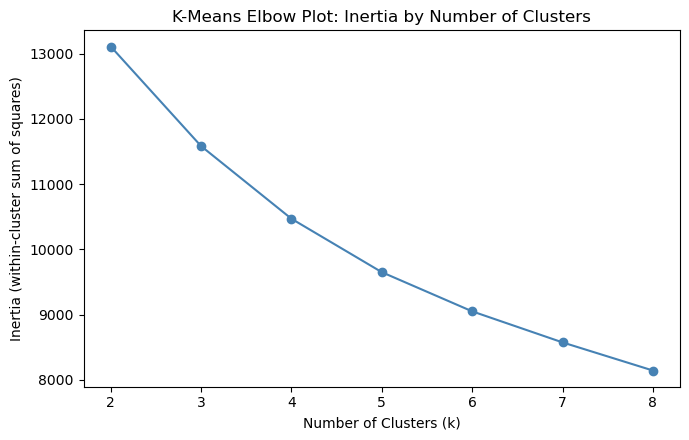

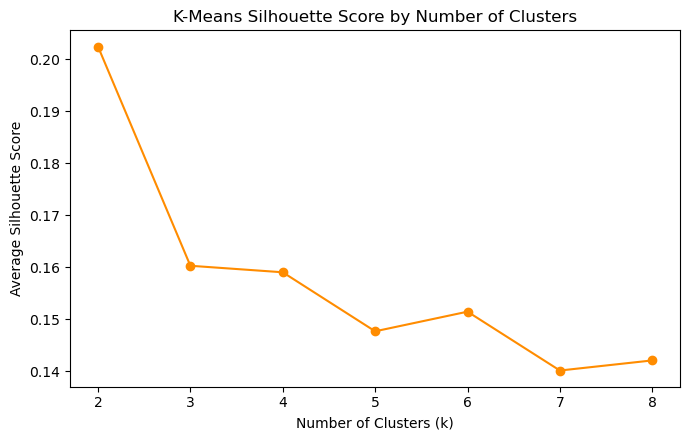

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(ks, inertias, marker='o', color='steelblue')
ax.set_title('K-Means Elbow Plot: Inertia by Number of Clusters')
ax.set_xlabel('Number of Clusters (k)')
ax.set_ylabel('Inertia (within-cluster sum of squares)')
plt.tight_layout()
plt.savefig('../images/clust_01_kmeans_elbow.png', dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(ks, sil_scores, marker='o', color='darkorange')
ax.set_title('K-Means Silhouette Score by Number of Clusters')
ax.set_xlabel('Number of Clusters (k)')
ax.set_ylabel('Average Silhouette Score')
plt.tight_layout()
plt.savefig('../images/clust_02_kmeans_silhouette.png', dpi=150)
plt.show()

In [10]:
sample_labels = sample_labels.copy()

for k in [2, 4, 6]:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    lab = km.fit_predict(Xs)
    sample_labels[f'k{k}'] = lab
    print(f"\n=== k={k}: clusters vs. position ===")
    print(pd.crosstab(sample_labels[f'k{k}'], sample_labels['position']))
    print(f"\n=== k={k}: average feature values per cluster ===")
    print(sample_raw.groupby(lab).mean().round(2))


=== k=2: clusters vs. position ===
position  Attack  Defender  Goalkeeper  Midfield  Missing
k2                                                       
0            308       495         151       381        3
1            215       219          38       190        0

=== k=2: average feature values per cluster ===
     age  height_in_cm  log_minutes  goals_per90  assists_per90  \
0  31.52        182.60         3.63         0.10           0.08   
1  26.46        182.23         3.78         0.15           0.11   

   yellows_per90  log_caps  log_value  
0           0.21      0.17       5.37  
1           0.18      2.17       6.47  

=== k=4: clusters vs. position ===
position  Attack  Defender  Goalkeeper  Midfield  Missing
k4                                                       
0            299        28           0       141        0
1             83       221          67       120        1
2             26       374         113       206        2
3            115        91         

In [11]:
print(sample_raw.groupby(sample_labels['k6']).mean().round(2).T)
print(sample_labels['k6'].value_counts().sort_index())

k6                  0       1       2       3       4       5
age             24.37   29.97   33.84   25.11   30.79   31.94
height_in_cm   186.26  179.93  185.17  178.72  183.62  179.43
log_minutes      3.45    3.47    3.78    3.71    4.16    3.71
goals_per90      0.06    0.06    0.04    0.27    0.09    0.25
assists_per90    0.04    0.06    0.03    0.19    0.08    0.17
yellows_per90    0.15    0.35    0.16    0.17    0.19    0.17
log_caps         0.88    0.20    0.16    2.37    3.20    0.17
log_value        6.10    5.42    5.27    6.76    6.27    5.45
k6
0    363
1    366
2    476
3    205
4    199
5    391
Name: count, dtype: int64


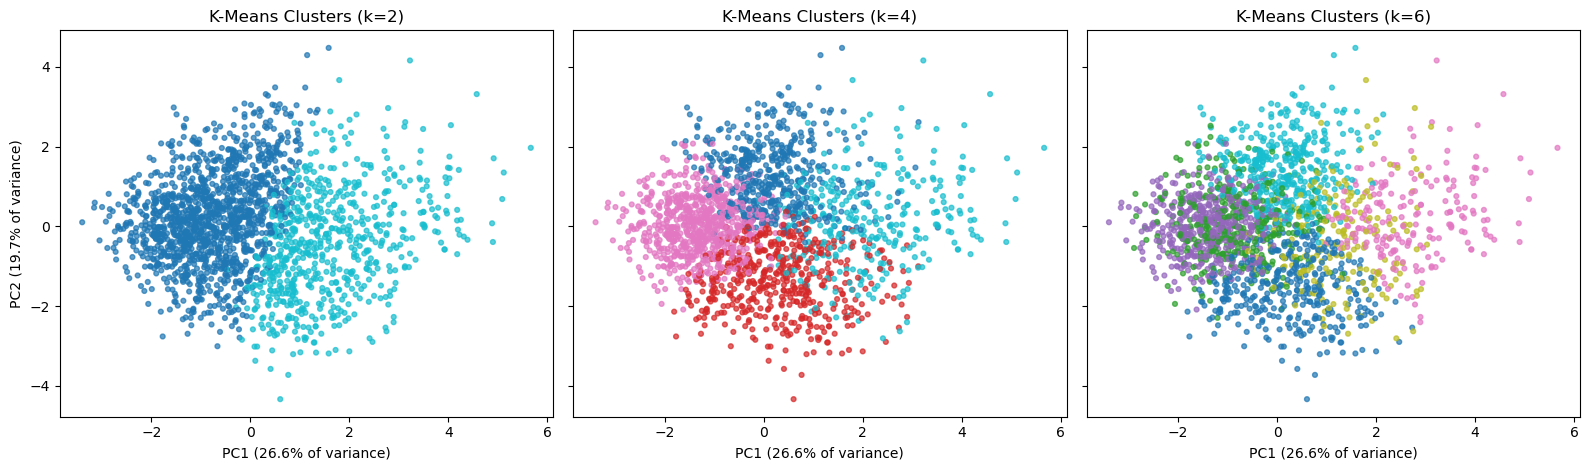

In [12]:
from sklearn.decomposition import PCA

pca2 = PCA(n_components=2, random_state=42)
coords = pca2.fit_transform(Xs)
ev = pca2.explained_variance_ratio_ * 100

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharex=True, sharey=True)
for ax, k in zip(axes, [2, 4, 6]):
    ax.scatter(coords[:, 0], coords[:, 1], c=sample_labels[f'k{k}'], cmap='tab10', s=12, alpha=0.7)
    ax.set_title(f'K-Means Clusters (k={k})')
    ax.set_xlabel(f'PC1 ({ev[0]:.1f}% of variance)')
axes[0].set_ylabel(f'PC2 ({ev[1]:.1f}% of variance)')
plt.tight_layout()
plt.savefig('../images/clust_03_kmeans_clusters_2d.png', dpi=150)
plt.show()

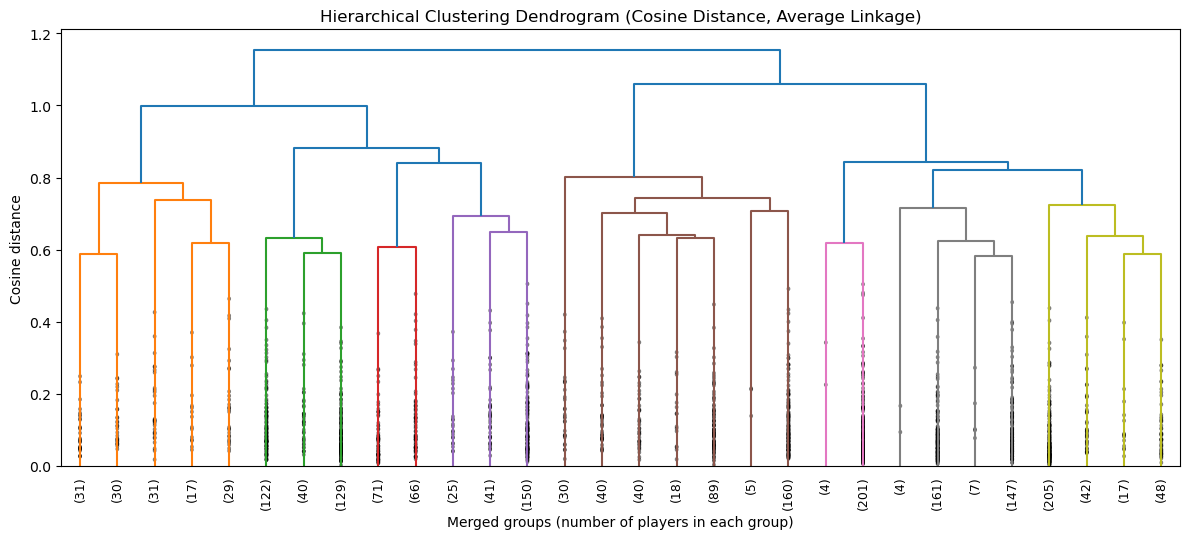

In [13]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist

D = pdist(Xs, metric='cosine')
Z = linkage(D, method='average')

fig, ax = plt.subplots(figsize=(12, 5.5))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90,
           leaf_font_size=9, show_contracted=True, ax=ax)
ax.set_title('Hierarchical Clustering Dendrogram (Cosine Distance, Average Linkage)')
ax.set_xlabel('Merged groups (number of players in each group)')
ax.set_ylabel('Cosine distance')
plt.tight_layout()
plt.savefig('../images/clust_04_dendrogram.png', dpi=150)
plt.show()

In [14]:
from sklearn.metrics import adjusted_rand_score

h_sil, ari = [], []
h_labels = {}
for k in ks:
    h_labels[k] = fcluster(Z, t=k, criterion='maxclust')
    h_sil.append(silhouette_score(Xs, h_labels[k], metric='cosine'))
    km_lab = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Xs)
    ari.append(adjusted_rand_score(km_lab, h_labels[k]))
    print(f"k={k}  silhouette(cosine)={h_sil[-1]:.4f}  ARI vs k-means={ari[-1]:.3f}  sizes={np.bincount(h_labels[k])[1:]}")

k=2  silhouette(cosine)=0.2525  ARI vs k-means=0.587  sizes=[ 782 1218]
k=3  silhouette(cosine)=0.2395  ARI vs k-means=0.525  sizes=[782 382 836]
k=4  silhouette(cosine)=0.2035  ARI vs k-means=0.479  sizes=[138 644 382 836]
k=5  silhouette(cosine)=0.1964  ARI vs k-means=0.405  sizes=[138 291 353 382 836]
k=6  silhouette(cosine)=0.1694  ARI vs k-means=0.345  sizes=[138 291 353 382 205 631]
k=7  silhouette(cosine)=0.1609  ARI vs k-means=0.391  sizes=[138 291 137 216 382 205 631]
k=8  silhouette(cosine)=0.1883  ARI vs k-means=0.414  sizes=[138 291 137 216 382 205 319 312]


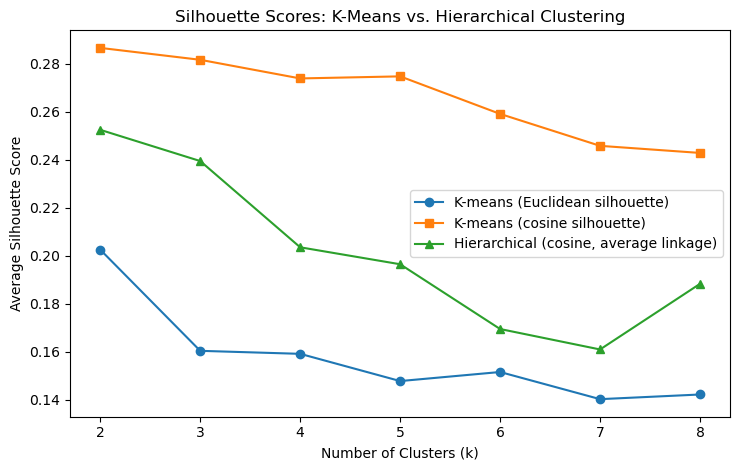

   k  kmeans_euclid  kmeans_cosine  hclust_cosine
0  2         0.2025         0.2867         0.2525
1  3         0.1603         0.2817         0.2395
2  4         0.1591         0.2739         0.2035
3  5         0.1477         0.2748         0.1964
4  6         0.1515         0.2591         0.1694
5  7         0.1401         0.2458         0.1609
6  8         0.1421         0.2429         0.1883

K-means (rows) vs. hierarchical (columns) at k=4:
col_0   1    2    3    4
row_0                   
0      23   31  353   61
1      69  282   18  123
2      34   28    9  650
3      12  303    2    2


In [15]:
km_labels, km_sil_cos = {}, []
for k in ks:
    km_labels[k] = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Xs)
    km_sil_cos.append(silhouette_score(Xs, km_labels[k], metric='cosine'))

fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.plot(ks, sil_scores, marker='o', label='K-means (Euclidean silhouette)')
ax.plot(ks, km_sil_cos, marker='s', label='K-means (cosine silhouette)')
ax.plot(ks, h_sil, marker='^', label='Hierarchical (cosine, average linkage)')
ax.set_title('Silhouette Scores: K-Means vs. Hierarchical Clustering')
ax.set_xlabel('Number of Clusters (k)')
ax.set_ylabel('Average Silhouette Score')
ax.legend()
plt.tight_layout()
plt.savefig('../images/clust_05_silhouette_comparison.png', dpi=150)
plt.show()

print(pd.DataFrame({'k': ks, 'kmeans_euclid': np.round(sil_scores, 4),
                    'kmeans_cosine': np.round(km_sil_cos, 4),
                    'hclust_cosine': np.round(h_sil, 4)}))

print("\nK-means (rows) vs. hierarchical (columns) at k=4:")
print(pd.crosstab(km_labels[4], h_labels[4]))

*PCA:*

     eigenvalue  variance_%  cumulative_%
PC1       2.126        26.6          26.6
PC2       1.577        19.7          46.3
PC3       1.342        16.8          63.1
PC4       0.996        12.5          75.6
PC5       0.788         9.9          85.5
PC6       0.533         6.7          92.1
PC7       0.407         5.1          97.2
PC8       0.223         2.8         100.0

Full-data variance %: [26.8 18.8 16.9 12.6 10.5  6.4  5.2  2.8]


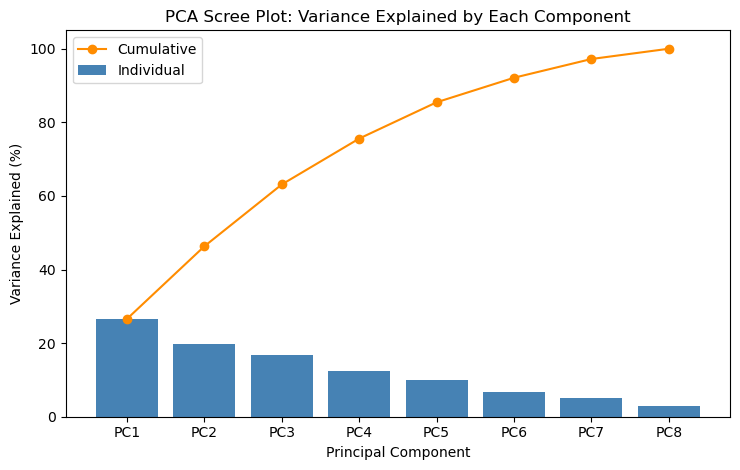

In [16]:
from sklearn.decomposition import PCA

pca = PCA(n_components=8, random_state=42)
scores = pca.fit_transform(Xs)

eig = pca.explained_variance_                      # eigenvalues
var = pca.explained_variance_ratio_ * 100
cum = np.cumsum(var)
pc_names = [f'PC{i}' for i in range(1, 9)]

print(pd.DataFrame({'eigenvalue': eig.round(3),
                    'variance_%': var.round(1),
                    'cumulative_%': cum.round(1)}, index=pc_names))

# robustness check: same PCA on all 17,218 players
full = PCA(n_components=8).fit(X_scaled.values)
print("\nFull-data variance %:", (full.explained_variance_ratio_ * 100).round(1))

fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.bar(pc_names, var, color='steelblue', label='Individual')
ax.plot(pc_names, cum, marker='o', color='darkorange', label='Cumulative')
ax.set_title('PCA Scree Plot: Variance Explained by Each Component')
ax.set_xlabel('Principal Component')
ax.set_ylabel('Variance Explained (%)')
ax.legend()
plt.tight_layout()
plt.savefig('../images/pca_01_scree.png', dpi=150)
plt.show()

                PC1   PC2   PC3   PC4
age           -0.38  0.49  0.43  0.01
height_in_cm  -0.16 -0.44  0.32 -0.29
log_minutes    0.16  0.25  0.68  0.26
goals_per90    0.33  0.37 -0.16 -0.37
assists_per90  0.38  0.50 -0.17 -0.14
yellows_per90 -0.09  0.09 -0.30  0.80
log_caps       0.47 -0.13  0.31  0.19
log_value      0.57 -0.29  0.09  0.13


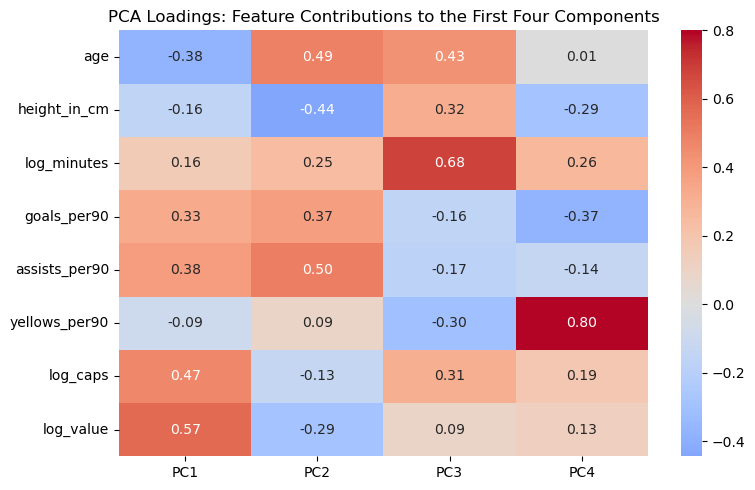

In [17]:
import seaborn as sns

loadings = pd.DataFrame(pca.components_.T, index=features, columns=pc_names)
print(loadings.iloc[:, :4].round(2))

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(loadings.iloc[:, :4], annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('PCA Loadings: Feature Contributions to the First Four Components')
plt.tight_layout()
plt.savefig('../images/pca_02_loadings.png', dpi=150)
plt.show()

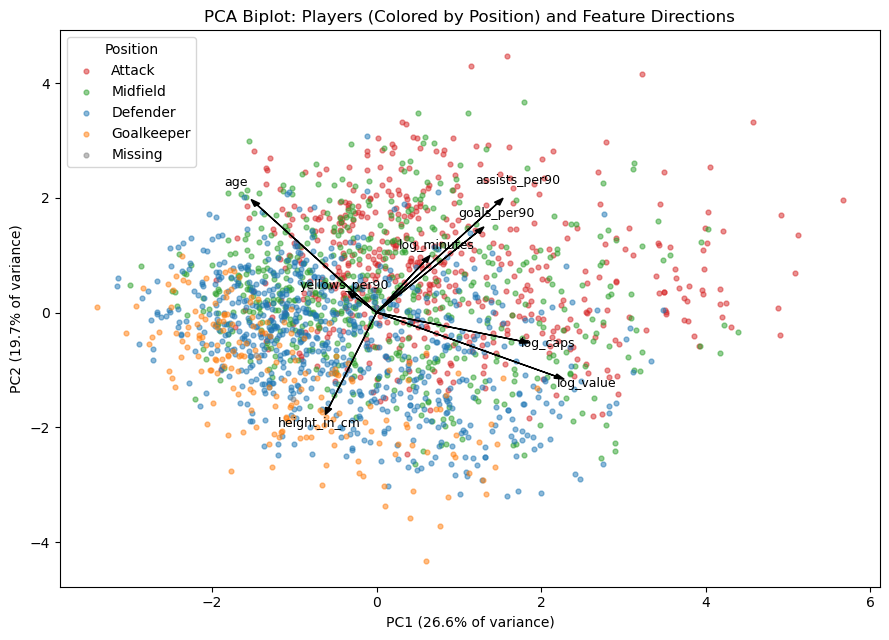

In [18]:
pos = sample_labels['position'].values
pos_colors = {'Attack': 'tab:red', 'Midfield': 'tab:green', 'Defender': 'tab:blue',
              'Goalkeeper': 'tab:orange', 'Missing': 'gray'}

fig, ax = plt.subplots(figsize=(9, 6.5))
for p, c in pos_colors.items():
    m = pos == p
    ax.scatter(scores[m, 0], scores[m, 1], s=12, alpha=0.5, c=c, label=p)

arrow_scale = 4
for i, f in enumerate(features):
    ax.arrow(0, 0, loadings.iloc[i, 0] * arrow_scale, loadings.iloc[i, 1] * arrow_scale,
             color='black', head_width=0.08, length_includes_head=True)
    ax.text(loadings.iloc[i, 0] * arrow_scale * 1.12, loadings.iloc[i, 1] * arrow_scale * 1.12,
            f, fontsize=9, ha='center')

ax.set_title('PCA Biplot: Players (Colored by Position) and Feature Directions')
ax.set_xlabel(f'PC1 ({var[0]:.1f}% of variance)')
ax.set_ylabel(f'PC2 ({var[1]:.1f}% of variance)')
ax.legend(title='Position')
plt.tight_layout()
plt.savefig('../images/pca_03_biplot.png', dpi=150)
plt.show()

In [19]:
Xc = Xs - Xs.mean(axis=0)
U, S, Vt = np.linalg.svd(Xc, full_matrices=False)

svd_eig = S**2 / (len(Xs) - 1)
print("Eigenvalues from SVD:", svd_eig.round(3))
print("Eigenvalues from PCA:", pca.explained_variance_.round(3))
print("Loadings match (up to sign):", np.allclose(np.abs(Vt), np.abs(pca.components_)))

Eigenvalues from SVD: [2.126 1.577 1.342 0.996 0.788 0.533 0.407 0.223]
Eigenvalues from PCA: [2.126 1.577 1.342 0.996 0.788 0.533 0.407 0.223]
Loadings match (up to sign): True


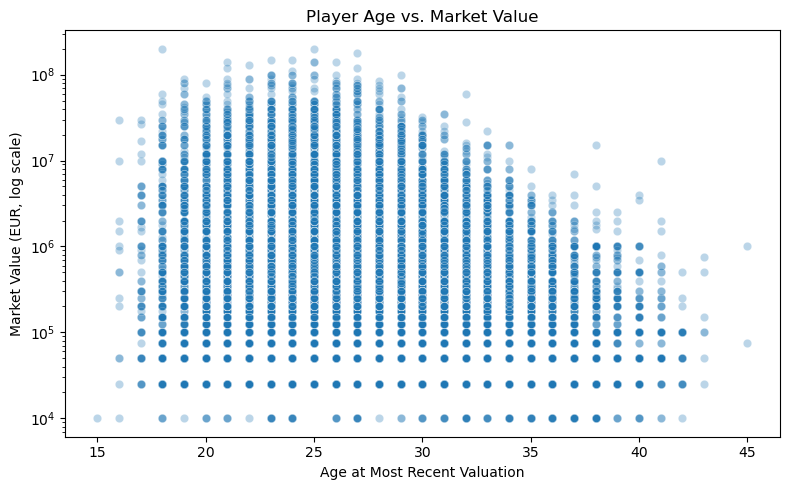

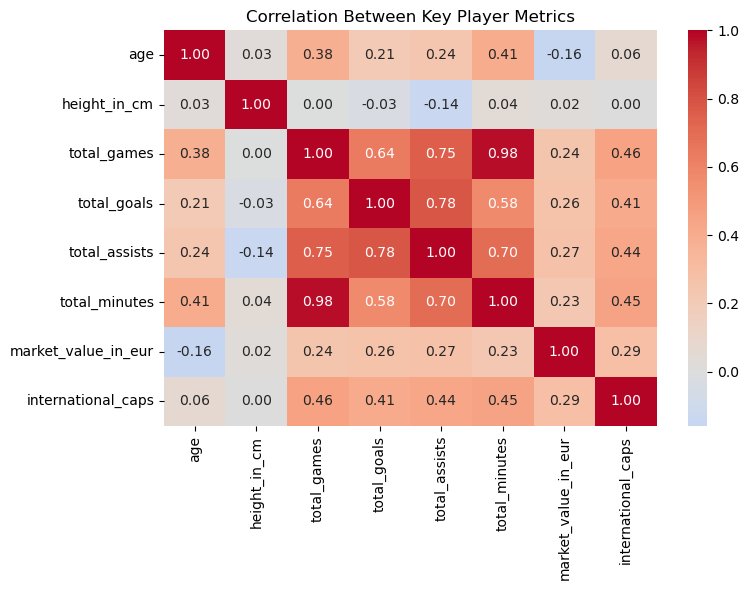

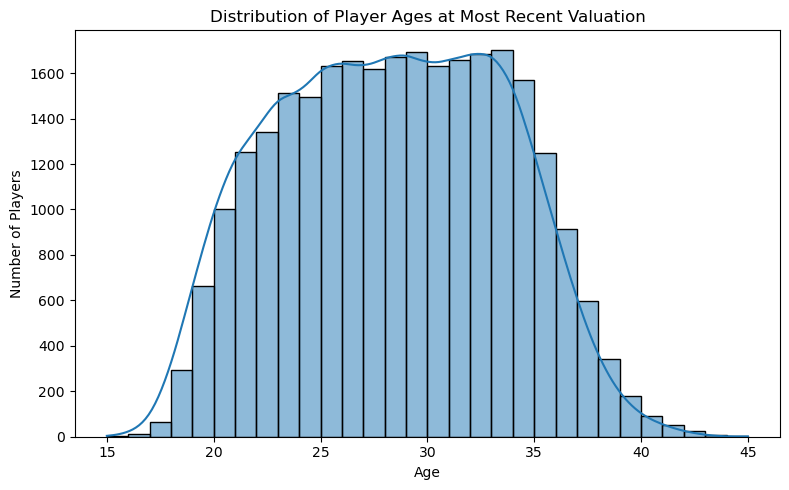

age
18    300000.0
19    300000.0
20    300000.0
21    362500.0
22    400000.0
23    500000.0
24    450000.0
25    500000.0
26    500000.0
27    500000.0
28    450000.0
29    400000.0
30    350000.0
31    300000.0
32    275000.0
33    250000.0
34    200000.0
35    175000.0
36    150000.0
37    100000.0
38    100000.0
Name: market_value_in_eur, dtype: float64
                      age  market_value_in_eur
age                  1.00                -0.16
market_value_in_eur -0.16                 1.00


In [20]:
import seaborn as sns

# 03: age vs. market value
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=df, x='age', y='market_value_in_eur', alpha=0.3, ax=ax)
ax.set_yscale('log')
ax.set_title('Player Age vs. Market Value')
ax.set_xlabel('Age at Most Recent Valuation')
ax.set_ylabel('Market Value (EUR, log scale)')
plt.tight_layout()
plt.savefig('../images/03_age_vs_value.png', dpi=150)
plt.show()

# 07: correlation heatmap
corr_cols = ['age', 'height_in_cm', 'total_games', 'total_goals', 'total_assists',
             'total_minutes', 'market_value_in_eur', 'international_caps']
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation Between Key Player Metrics')
plt.tight_layout()
plt.savefig('../images/07_correlation_heatmap.png', dpi=150)
plt.show()

# 10: age distribution
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(df['age'], binwidth=1, kde=True, ax=ax)
ax.set_title('Distribution of Player Ages at Most Recent Valuation')
ax.set_xlabel('Age')
ax.set_ylabel('Number of Players')
plt.tight_layout()
plt.savefig('../images/10_age_distribution.png', dpi=150)
plt.show()

# numbers to check your captions against
print(df.groupby('age')['market_value_in_eur'].median().loc[18:38])
print(df[['age', 'market_value_in_eur']].corr().round(2))

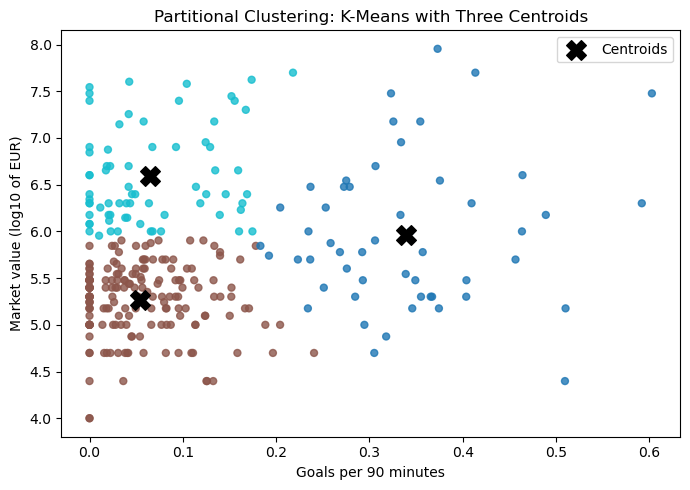

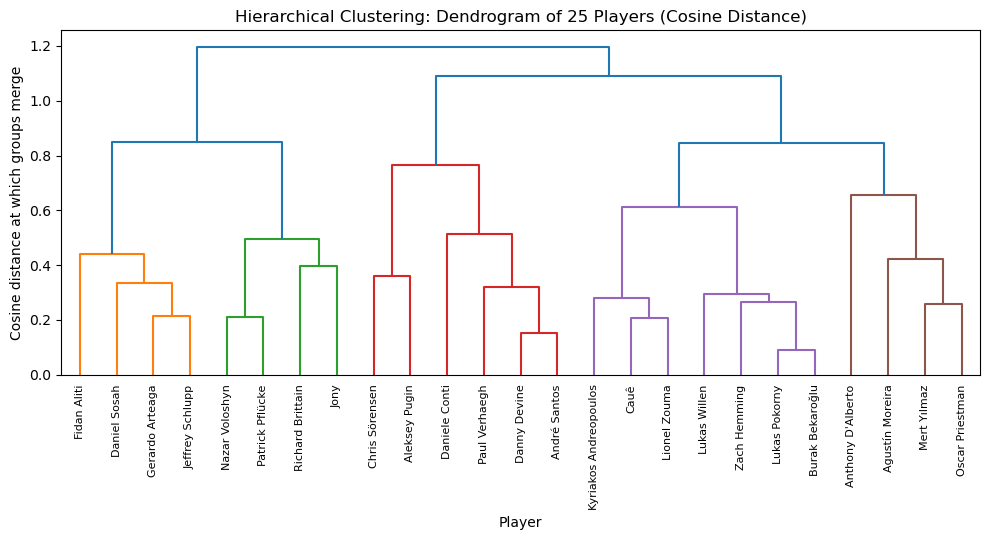

In [26]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage as lk

# 1) K-means with centroids: goals per 90 vs. market value
sub = sample_raw.sample(300, random_state=7)
cols = ['goals_per90', 'log_value']
sc = StandardScaler().fit(sub[cols])
km = KMeans(n_clusters=3, n_init=10, random_state=7).fit(sc.transform(sub[cols]))
centers = sc.inverse_transform(km.cluster_centers_)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(sub['goals_per90'], sub['log_value'], c=km.labels_, cmap='tab10', s=25, alpha=0.8)
ax.scatter(centers[:, 0], centers[:, 1], c='black', marker='X', s=200, label='Centroids')
ax.set_title('Partitional Clustering: K-Means with Three Centroids')
ax.set_xlabel('Goals per 90 minutes')
ax.set_ylabel('Market value (log10 of EUR)')
ax.legend()
plt.tight_layout()
plt.savefig('../images/clust_ov_01_kmeans_toy.png', dpi=150)
plt.show()

# 2) Dendrogram of 25 named players (cosine distance, average linkage)
pick = sample_scaled.sample(25, random_state=7).index
names = sample_labels.loc[pick, 'name'].tolist()
Zp = lk(sample_scaled.loc[pick].values, method='average', metric='cosine')

fig, ax = plt.subplots(figsize=(10, 5.5))
dendrogram(Zp, labels=names, leaf_rotation=90, leaf_font_size=8, ax=ax)
ax.set_title('Hierarchical Clustering: Dendrogram of 25 Players (Cosine Distance)')
ax.set_xlabel('Player')
ax.set_ylabel('Cosine distance at which groups merge')
plt.tight_layout()
plt.savefig('../images/clust_ov_02_dendrogram_toy.png', dpi=150)
plt.show()

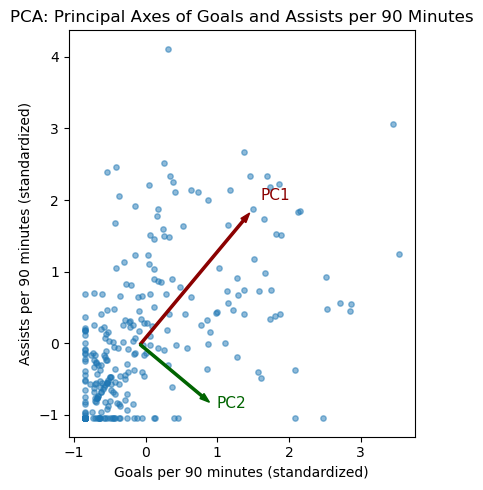

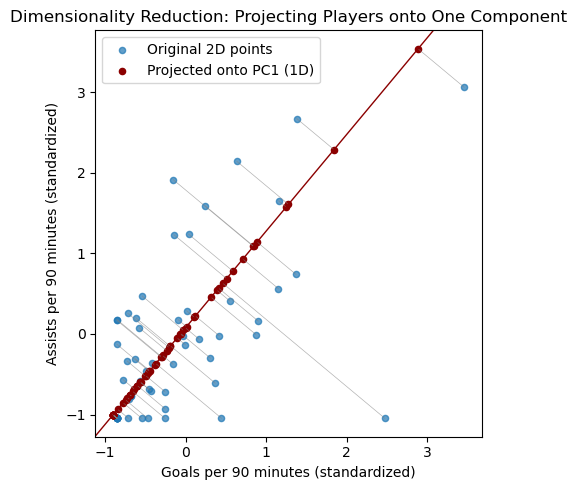

In [28]:
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(P[:, 0], P[:, 1], s=15, alpha=0.5)
for comp, ev_, name, col in zip(pc.components_, pc.explained_variance_,
                                ['PC1', 'PC2'], ['darkred', 'darkgreen']):
    dx, dy = comp * np.sqrt(ev_) * 2
    ax.arrow(pc.mean_[0], pc.mean_[1], dx, dy, color=col, width=0.03, length_includes_head=True)
    ax.text(pc.mean_[0] + dx * 1.1, pc.mean_[1] + dy * 1.1, name, color=col, fontsize=11)
ax.set_aspect('equal')
ax.set_title('PCA: Principal Axes of Goals and Assists per 90 Minutes')
ax.set_xlabel('Goals per 90 minutes (standardized)')
ax.set_ylabel('Assists per 90 minutes (standardized)')
plt.tight_layout()
plt.savefig('../images/pca_ov_01_axes_toy.png', dpi=150)
plt.show()

# 4) Projection of 60 of those players onto PC1
sub2 = P[:60]
pc1 = pc.components_[0]
proj = ((sub2 - pc.mean_) @ pc1)[:, None] * pc1 + pc.mean_
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(sub2[:, 0], sub2[:, 1], s=20, alpha=0.7, label='Original 2D points')
ax.scatter(proj[:, 0], proj[:, 1], s=20, color='darkred', label='Projected onto PC1 (1D)')
for a, b in zip(sub2, proj):
    ax.plot([a[0], b[0]], [a[1], b[1]], color='gray', lw=0.5, alpha=0.6)
ax.axline(tuple(pc.mean_), slope=pc1[1] / pc1[0], color='darkred', lw=1)
ax.set_aspect('equal')
ax.set_title('Dimensionality Reduction: Projecting Players onto One Component')
ax.set_xlabel('Goals per 90 minutes (standardized)')
ax.set_ylabel('Assists per 90 minutes (standardized)')
ax.legend()
plt.tight_layout()
plt.savefig('../images/pca_ov_02_projection_toy.png', dpi=150)
plt.show()

In [24]:
import dataframe_image as dfi

dfi.export(sample_raw.head().round(2), '../images/clust_sample_raw.png',
           table_conversion='matplotlib')
dfi.export(sample_scaled.head().round(2), '../images/clust_sample_scaled.png',
           table_conversion='matplotlib')

print("saved")

saved
